# 04 - Human Activity Recognition: CNN + LSTM

```
video -> 16 frames -> MobileNetV2 (CNN) -> 16 x 1280 features -> windows of 8 -> LSTM -> activity
```

* The **CNN** looks at each frame on its own (what is in the picture).
* The **LSTM** reads the frames **in order** (how things change over time), which is what separates walking from standing.

> **Honest scope:** the supplied dataset has only 4 videos (Walking x2, Sitting, Standing). This notebook proves the pipeline works end to end; the accuracy numbers are **not** statistically meaningful. To get a real model, add more videos to `datasets/human_activity` and re-run.

In [1]:
# Make the project importable and use the project root as working folder
import os, sys
from pathlib import Path

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
print("Project root:", ROOT)

Project root: e:\AI ENGINEER INTERVIEW PREPARATION\Smart-Surveillance-AI_Project


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import accuracy_score

from src.config import *
from src.activity_detection import load_activity_dataset, predict_video

tf.keras.utils.set_random_seed(SEED)
print("TensorFlow", tf.__version__)


TensorFlow 2.15.1


## 1. Build sequence data

In [3]:
# 1) MobileNetV2 (frozen CNN) turns every frame into a 1280-d feature vector
# 2) the 16 frames of each video are cut into overlapping windows of 8 frames
# (first run downloads the MobileNetV2 ImageNet weights)
X, y, groups = load_activity_dataset()

print("X:", X.shape, "(windows, frames per window, features)")
print("windows per class:", {ACTIVITY_CLASSES[i]: int((y == i).sum()) for i in range(len(ACTIVITY_CLASSES))})
print("source videos:", sorted(set(groups)))



X: (20, 8, 1280) (windows, frames per window, features)
windows per class: {'Sitting': 5, 'Standing': 5, 'Walking': 10}
source videos: ['AmericanGangster_sit', 'Finding_Forrester_1_walk', 'Shadow_of_a_Doubt_stand', 'TheLastManOnearth_walk']


## 2. LSTM model
`LayerNormalization` rescales the CNN features, `GaussianNoise` is a light augmentation (training only), the `LSTM` summarises the 8-frame sequence into one vector, and a softmax layer outputs the activity.

In [4]:
def build_cnn_lstm():
    inputs = keras.Input(shape=(ACTIVITY_WINDOW, ACTIVITY_FEATURE_DIM))
    x = layers.LayerNormalization()(inputs)
    x = layers.GaussianNoise(0.1)(x)
    x = layers.LSTM(64)(x)
    x = layers.Dropout(0.5)(x)
    x = layers.Dense(32, activation="relu")(x)
    outputs = layers.Dense(len(ACTIVITY_CLASSES), activation="softmax")(x)
    return keras.Model(inputs, outputs, name="activity_cnn_lstm")


build_cnn_lstm().summary()

Model: "activity_cnn_lstm"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, 8, 1280)]         0         
                                                                 
 layer_normalization (Layer  (None, 8, 1280)           2560      
 Normalization)                                                  
                                                                 
 gaussian_noise (GaussianNo  (None, 8, 1280)           0         
 ise)                                                            
                                                                 
 lstm (LSTM)                 (None, 64)                344320    
                                                                 
 dropout (Dropout)           (None, 64)                0         
                                                                 
 dense (Dense)               (None, 32)          

## 3. Training helpers and a held-out-video check

In [5]:
def train_model(builder, X_tr, y_tr, epochs=60):
    tf.keras.utils.set_random_seed(SEED)
    model = builder()
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    history = model.fit(X_tr, y_tr, epochs=epochs, batch_size=8, verbose=0)
    return model, history


# Held-out-video check: train WITHOUT one Walking video, then test on it.
# (Windows of one video are almost identical, so we never split inside a video.)
HELD_OUT = "Finding_Forrester_1_walk"


def held_out_check(builder):
    test_mask = groups == HELD_OUT
    model, _ = train_model(builder, X[~test_mask], y[~test_mask])
    pred = model.predict(X[test_mask], verbose=0).argmax(axis=1)
    acc = accuracy_score(y[test_mask], pred)
    print(f"held-out video '{HELD_OUT}': predicted", [ACTIVITY_CLASSES[i] for i in pred], "-> accuracy", round(acc, 2))
    return acc

In [6]:
held_out_check(build_cnn_lstm)



held-out video 'Finding_Forrester_1_walk': predicted ['Sitting', 'Sitting', 'Sitting', 'Sitting', 'Sitting'] -> accuracy 0.0


0.0

## 4. Train the final model on all videos
This is the model the API will use. Its training accuracy only shows that the pipeline learns; it says nothing about real-world performance.

final training accuracy: 1.0


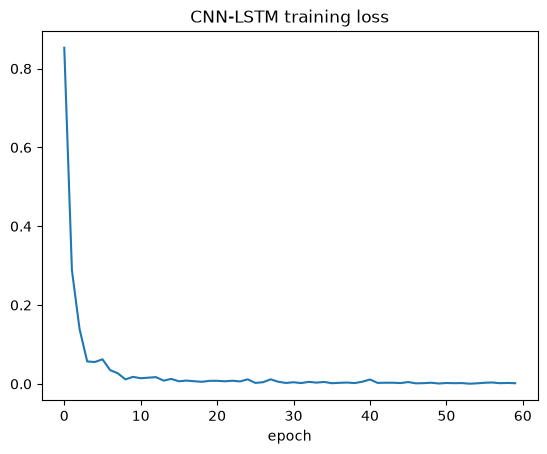

Saved: E:\AI ENGINEER INTERVIEW PREPARATION\Smart-Surveillance-AI_Project\models\activity_cnn_lstm.keras


In [7]:
model, history = train_model(build_cnn_lstm, X, y, epochs=60)
print("final training accuracy:", round(history.history["accuracy"][-1], 3))

plt.plot(history.history["loss"])
plt.title("CNN-LSTM training loss"); plt.xlabel("epoch"); plt.show()

model.save(ACTIVITY_CNN_LSTM_PATH)
print("Saved:", ACTIVITY_CNN_LSTM_PATH)

## 5. Test with the project's inference code (video file in, activity out)

In [8]:
labels_df = pd.read_csv(ACTIVITY_LABELS_CSV)
for _, row in labels_df.iterrows():
    result = predict_video(ACTIVITY_DIR / row["video_path"], model_type="cnn_lstm")
    print(f"true={row['label']:9s} predicted={result['label']:9s} confidence={result['confidence']:.2f}")

true=Walking   predicted=Walking   confidence=1.00
true=Walking   predicted=Walking   confidence=1.00
true=Sitting   predicted=Sitting   confidence=1.00
true=Standing  predicted=Standing  confidence=1.00


**Done:** `models/activity_cnn_lstm.keras` is saved. Next: notebook 05 (BiLSTM).